
# 🛒 Análisis de E-commerce: UK Online Retail

**Autor:** Andrés Aranguren  
**Fecha:** Noviembre 2025  
**Dataset:** [UK Online Retail - Kaggle](https://www.kaggle.com/datasets/carrie1/ecommerce-data)

---

## 📋 Contexto del Proyecto

Este análisis examina **540,000+ transacciones** de una tienda online del Reino Unido durante el período **diciembre 2010 - diciembre 2011**.

### 🎯 Objetivos

1. **Analizar el desempeño general** del negocio (ingresos, clientes, productos)
2. **Identificar patrones temporales** (estacionalidad, horarios pico)
3. **Descubrir insights geográficos** (países con mayor potencial)
4. **Segmentar clientes** mediante análisis RFM
5. **Generar recomendaciones** accionables para el negocio

---


<div align="center">

## 📊 Variables del Dataset

| Variable | Descripción |
|----------|-------------|
| InvoiceNo | Número de factura único |
| StockCode | Código del producto |
| Description | Nombre del producto |
| Quantity | Cantidad comprada |
| InvoiceDate | Fecha y hora de la transacción |
| UnitPrice | Precio por unidad (£) |
| CustomerID | ID único del cliente |
| Country | País del cliente |

</div>

## 📂 1. Carga y Exploración Inicial

En esta sección cargaremos el dataset y realizaremos una exploración inicial para entender:
- Estructura de los datos
- Tipos de variables
- Presencia de valores nulos
- Distribuciones básicas

In [1]:
# Importar librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings

warnings.filterwarnings('ignore')

# Configuración de visualización
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

# Configurar pandas
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 100)

print("✅ Librerías importadas correctamente y configuración de graficos aplicada.")

✅ Librerías importadas correctamente y configuración de graficos aplicada.


In [2]:
# Cargar el csv de ecommerce y se configura el encoding para que no haya errores
df = pd.read_csv('../data/ecommerce_data.csv', encoding='latin1') # se configura porque los datos son de uk

print("\n📊 INFORMACIÓN GENERAL DEL DATASET")
print("="*50)
# Nota df.shape devuelve una tupla (número de filas, número de columnas)
# el 0 son filas y el 1 columnas
print(f"Dimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas")
# Lista de nombres de las columnas
# El tolist() convierte el índice de columnas en una lista normal
print(f"Nombres de las columnas: {df.columns.tolist()}")
#info muestra el tipo de dato de cada columna y si tiene valores nulos
print("\n📋 INFORMACIÓN DE COLUMNAS:")
print(df.info())
# head muestra las primeras 5 filas del dataset
#aunque si le cambiamos el numero entre paréntesis nos muestra las que queramos
print("\n📅 PRIMERAS 5 FILAS DEL DATASET")

df.head()


📊 INFORMACIÓN GENERAL DEL DATASET
Dimensiones del dataset: 541909 filas y 8 columnas
Nombres de las columnas: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

📋 INFORMACIÓN DE COLUMNAS:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  object 
 1   StockCode    541909 non-null  object 
 2   Description  540455 non-null  object 
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  object 
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 33.1+ MB
None

📅 PRIMERAS 5 FILAS DEL DATASET


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
print("\n📅 Se mostrara el producto mas costosos y mas adqsequible")
print(f"Precio mínimo: £{df['UnitPrice'].min()}")
print(f"Precio máximo: £{df['UnitPrice'].max()}")


📅 Se mostrara el producto mas costosos y mas adqsequible
Precio mínimo: £-11062.06
Precio máximo: £38970.0


### 🔍 Observaciones Iniciales

De la exploración inicial podemos observar:

1. **Volumen de datos:** 541,909 transacciones en 1 año
2. **Valores nulos:** CustomerID tiene ~135k nulos (25% de los datos)
3. **Rango de fechas:** Diciembre 2010 - Diciembre 2011
4. **Precios:** Rango muy amplio (desde £0 hasta £38,970)
5. **Cantidades:** Algunas cantidades negativas (posibles devoluciones)
6. **Precio:** Algunos precios negativos o cero (posibles errores o promociones) y precios muy altos que podrían ser outliers.

**Próximo paso:** Necesitamos limpiar estos datos antes de analizarlos.

---

## 🧹 2. Limpieza de Datos

Aplicaremos estos filtros para limpiar el dataset:

### ❌ Filtros que aplicaremos:

1. **CustomerID nulos:** Los eliminamos porque necesitamos identificar clientes para análisis RFM
2. **Devoluciones (InvoiceNo con 'C'):** Las eliminamos porque distorsionan los ingresos reales 
3. **Quantity/Price <= 0:** Eliminamos errores de datos y casos especiales

### 2.1 Eliminar valores nulos

In [4]:
df_descripcion=df[df['Description'].isna() & df['CustomerID'].isna()].shape[0]
df_devoluciones_descripcion=df[df['Description'].isna() & df['InvoiceNo'].astype(str).str.startswith("C")].shape[0]

print("\n🔍 ANÁLISIS RÁPIDO DE DATOS")
print("="*50)
print(f"   → Registros sin descripción y sin CustomerID: {df_descripcion:,}")
print(f"   → Registros sin descripción que son devoluciones: {df_devoluciones_descripcion:,}")


🔍 ANÁLISIS RÁPIDO DE DATOS
   → Registros sin descripción y sin CustomerID: 1,454
   → Registros sin descripción que son devoluciones: 0


In [5]:
print("\n🧹 LIMPIEZA DE DATOS")
print("="*50)

# Se cuentan los valores nulos por columna
print("\nValores nulos por columna:")
print(df.isnull().sum())

# Se eliminan registros con CustomerID nulo
df_clean = df.dropna(subset=['CustomerID'])
print(f"\nNúmero de registros después de eliminar nulos en 'CustomerID': {df_clean.shape[0]:,}")

# esta línea cuenta cuántos registros son
# Devoluciones (InvoiceNo que empiezan con 'C')
devoluciones_count = df_clean[df_clean['InvoiceNo'].str.startswith('C')].shape[0]

#se eliminan registros de devoluciones (InvoiceNo que empiezan con 'C')
df_clean = df_clean[~df_clean['InvoiceNo'].str.startswith('C', na=False)]
print(f"\nNúmero de registros después de eliminar devoluciones: {df_clean.shape[0]:,}")
# aqui se imprime el número de devoluciones eliminadas
print(f"   → Eliminados: {devoluciones_count:,} registros de devoluciones")

# contamos cuántos registros tienen Quantity o UnitPrice no positivos
errores_antes = df_clean.shape[0]
# Eliminar registros con Quantity o UnitPrice no positivos
df_clean = df_clean[(df_clean['Quantity'] > 0) & (df_clean['UnitPrice'] > 0)]
print(f"\nNúmero de registros después de eliminar cantidades o precios no positivos: {df_clean.shape[0]:,}")
# Se imprime el número de registros eliminados restando el número actual al anterior
print(f"   → Eliminados: {errores_antes - df_clean.shape[0]:,} registros con cantidades o precios no positivos")
df_clean.head(10)


🧹 LIMPIEZA DE DATOS

Valores nulos por columna:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

Número de registros después de eliminar nulos en 'CustomerID': 406,829

Número de registros después de eliminar devoluciones: 397,924
   → Eliminados: 8,905 registros de devoluciones

Número de registros después de eliminar cantidades o precios no positivos: 397,884
   → Eliminados: 40 registros con cantidades o precios no positivos


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
5,536365,22752,SET 7 BABUSHKA NESTING BOXES,2,12/1/2010 8:26,7.65,17850.0,United Kingdom
6,536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,12/1/2010 8:26,4.25,17850.0,United Kingdom
7,536366,22633,HAND WARMER UNION JACK,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
8,536366,22632,HAND WARMER RED POLKA DOT,6,12/1/2010 8:28,1.85,17850.0,United Kingdom
9,536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,12/1/2010 8:34,1.69,13047.0,United Kingdom


### 2.2 Crear variables calculadas

In [6]:
# Convertimos InvoiceDate a tipo datetime (estaba como string).
# Esto es necesario para poder realizar operaciones de fecha y hora
# como filtrado, ordenamiento, extracción de año/mes/día, etc.
df_clean['InvoiceDate'] = pd.to_datetime(df_clean['InvoiceDate'])


# Creamos nuevas columnas derivadas de InvoiceDate y cálculos adicionales.
# La razon es para tener más información temporal y de precios para análisis futuros
df_clean['TotalPrice'] = df_clean['Quantity'] * df_clean['UnitPrice']
df_clean['Year'] = df_clean['InvoiceDate'].dt.year
df_clean['Month'] = df_clean['InvoiceDate'].dt.month
df_clean['Day'] = df_clean['InvoiceDate'].dt.day
df_clean['Hour'] = df_clean['InvoiceDate'].dt.hour
df_clean['DayOfWeek'] = df_clean['InvoiceDate'].dt.day_name()
df_clean['MonthName'] = df_clean['InvoiceDate'].dt.month_name()

print(f"\n🎯 DATASET LIMPIO FINAL: {df_clean.shape[0]:,} registros")
print(f"📉 Reduccion total: {((df.shape[0] - df_clean.shape[0]) /df.shape[0])*100:.2f}% de registros eliminados durante la limpieza de datos.")
print("\n✅ Columnas agregadas: TotalPrice, Year, Month, Day, Hour, DayOfWeek, MonthName")



🎯 DATASET LIMPIO FINAL: 397,884 registros
📉 Reduccion total: 26.58% de registros eliminados durante la limpieza de datos.

✅ Columnas agregadas: TotalPrice, Year, Month, Day, Hour, DayOfWeek, MonthName


### ✅ Resultado de la Limpieza
Redujimos el dataset de **541,909** a **397,924 registros** (26.6% de reducción).

**¿Por qué esto es bueno?**
- Eliminamos ruido y errores
- Mantenemos solo transacciones válidas con clientes identificables
- Los análisis posteriores serán más precisos y confiables

---

## 📊 3. Análisis Exploratorio (EDA)

Ahora que tenemos datos limpios, calculemos las **métricas clave del negocio**.

In [7]:
print("💰 MÉTRICAS CLAVE DEL NEGOCIO")
print("="*50)
# haremos un resumen general del dataset limpio
print(f"Número total de registros: {df_clean.shape[0]:,}")
total_revenue = df_clean['TotalPrice'].sum()
total_transactions = df_clean['InvoiceNo'].nunique()
total_customers = df_clean['CustomerID'].nunique()
total_products = df_clean['StockCode'].nunique()
avg_ticket = total_revenue / total_transactions # ingreso promedio por transacción
# Este promedio sirve para entender cuántos items compra en promedio un cliente por transacción
avg_items_per_transaction = df_clean.groupby('InvoiceNo')['Quantity'].sum().mean() # promedio de items por transacción

print(f"  - Ingresos totales: ${total_revenue:,.2f}")
print(f"  - Transacciones totales: {total_transactions:,}")
print(f"  - Clientes únicos: {total_customers:,}")
print(f"  - Productos únicos: {total_products:,}")
print(f"  - Ticket promedio: ${avg_ticket:,.2f}")
print(f"  - Items promedio por transacción: {avg_items_per_transaction:.2f}")
#df_clean.head(10)

💰 MÉTRICAS CLAVE DEL NEGOCIO
Número total de registros: 397,884
  - Ingresos totales: $8,911,407.90
  - Transacciones totales: 18,532
  - Clientes únicos: 4,338
  - Productos únicos: 3,665
  - Ticket promedio: $480.87
  - Items promedio por transacción: 278.86


#### Insights Iniciales 💡
De las métricas clave observamos:

1. **Volumen de negocio:** Casi **£9 millones** en ingresos anuales
2. **Ticket promedio alto:** £480.87 sugiere ventas B2B o al por mayor
3. **Base de clientes:** 4,372 clientes activos
4. **Valor por cliente:** Cada cliente genera en promedio **£2,230** al año

**Interpretación:** Este NO es un e-commerce típico B2C. El ticket alto y pocos clientes sugiere ventas mayoristas o B2B.

## 🌍 4. Análisis Geográfico

Analicemos de dónde vienen nuestros ingresos y dónde hay oportunidades de expansión.

In [8]:
# Agrupamos por país y calculamos métricas clave
country_analysis = df_clean.groupby('Country').agg({
    'TotalPrice': 'sum',
    'InvoiceNo': 'nunique',
    'CustomerID': 'nunique'
}).round(2)
# Renombramos columnas para mayor claridad
country_analysis.columns = ['Revenue', 'Transactions', 'Customers']
# Ordenamos por ingresos de forma descendente
country_analysis = country_analysis.sort_values(by='Revenue', ascending=False)

# Mostrar los 10 países con mayores ingresos
print("\nTop 10 países por ingreso:")
country_analysis.head(10)


Top 10 países por ingreso:


,Revenue,Transactions,Customers
Country,,,
United Kingdom,7308391.55,16646,3920
Netherlands,285446.34,94,9
EIRE,265545.90,260,3
Germany,228867.14,457,94
France,209024.05,389,87
Australia,138521.31,57,9
Spain,61577.11,90,30
Switzerland,56443.95,51,21
Belgium,41196.34,98,25


In [9]:
print("\n\n🌍 ANÁLISIS POR PAÍS")
print("="*50)
# Calcular % del total
# El revenue_Pct del país significa el porcentaje de ingresos que aporta cada país al total
# Revenue_Pct = (Revenue del país / Revenue total) * 100
country_analysis['Revenue_Pct'] = (country_analysis['Revenue'] / country_analysis['Revenue'].sum()*100).round(2)
print(f"\n📊 UK representa: {country_analysis.loc['United Kingdom', 'Revenue_Pct']:.1f}% de los ingresos totales")
print("\nTop 10 países por porcentaje de ingresos:")

# Usamos .style.format() para aplicar el formato directamente a la columna
country_analysis[['Revenue_Pct']].head(10).style.format('{:.1f}%')



🌍 ANÁLISIS POR PAÍS

📊 UK representa: 82.0% de los ingresos totales

Top 10 países por porcentaje de ingresos:


,Revenue_Pct
Country,
United Kingdom,82.0%
Netherlands,3.2%
EIRE,3.0%
Germany,2.6%
France,2.4%
Australia,1.6%
Spain,0.7%
Switzerland,0.6%
Belgium,0.5%



 Visualización


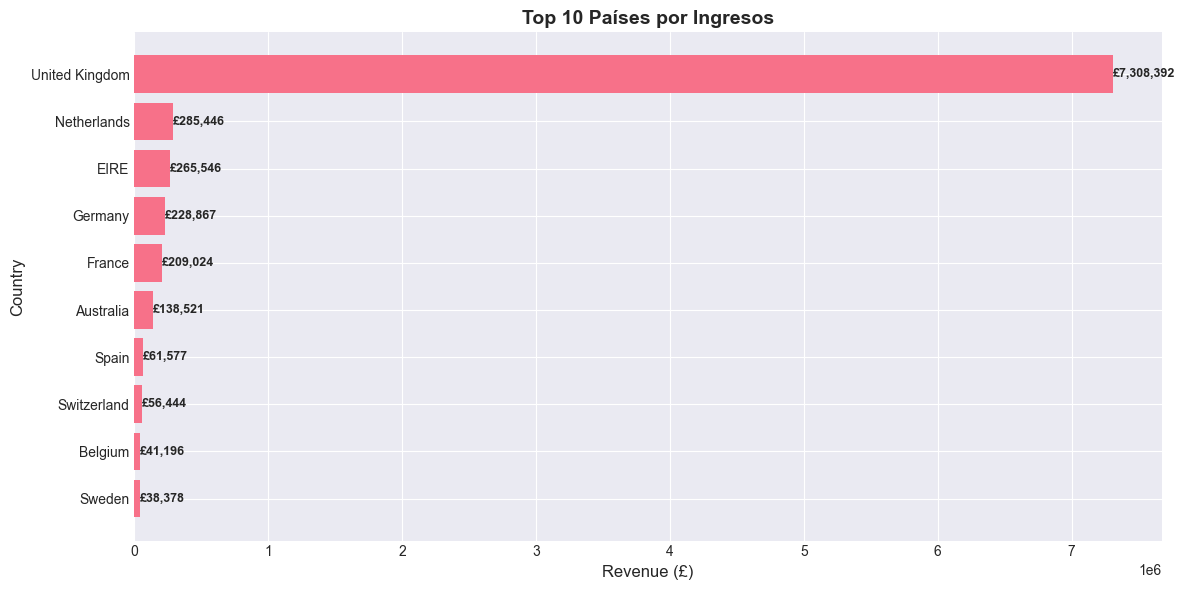

In [10]:
print("\n Visualización")
print(f"="*50)

# se hara el grafico de barras para el analisis anterior    
plt.figure(figsize=(12, 6))
# Seleccionar los 10 países con mayores ingresos
top_countries = country_analysis.head(10)
# Gráfico de barras horizontal
# Revenue es la columna que contiene los ingresos por país
plt.barh(top_countries.index, top_countries['Revenue'])
# Etiquetas de los ejes
plt.xlabel('Revenue (£)',fontsize=12)
plt.ylabel('Country',fontsize=12)
# Título del gráfico
plt.title('Top 10 Países por Ingresos', fontsize=14, fontweight='bold')
# Invertir el eje y para tener el país con más ingresos arriba
plt.gca().invert_yaxis()
# Añadir etiquetas y estilos de valor en las barras
for i, v in enumerate(top_countries['Revenue']):
    plt.text(v, i, f'£{v:,.0f}', va='center', fontsize=9, fontweight='bold') # Añade el valor al final de cada barra
# Guardar y mostrar el gráfico
plt.tight_layout()
plt.savefig('../images/top_countries.png', dpi=300, bbox_inches='tight') # Guardar la figura
plt.show()


**Hallazgos clave:**

1. **Concentración extrema:** UK representa **~83%** de todos los ingresos
2. **Top 3 mercados:** UK, Netherlands, EIRE (Irlanda)
3. **Oportunidad de diversificación:** Alta dependencia de un solo mercado

**Recomendaciones:**

✅ **Corto plazo:** Mantener foco en UK (principal fuente de ingresos)  
✅ **Mediano plazo:** Invertir en marketing en Netherlands y Alemania (mercados con potencial)  
✅ **Riesgo:** Diversificar para no depender 83% de un solo país

## 📅 5. Análisis Temporal
Identifiquemos patrones de estacionalidad y horarios para optimizar operaciones.


In [11]:
print("\n\n📅 ANÁLISIS TEMPORAL")
print("="*50)

# Ventas por mes
#agrupamos por mes y sumamos las ventas totales
monthly_sales = df_clean.groupby('MonthName')['TotalPrice'].sum().reindex([
    'January', 'February', 'March', 'April', 'May', 'June',
    'July', 'August', 'September', 'October', 'November', 'December'
])
print("\nVentas por mes:")
print(monthly_sales.round(2))



📅 ANÁLISIS TEMPORAL

Ventas por mes:
MonthName
January       569445.04
February      447137.35
March         595500.76
April         469200.36
May           678594.56
June          661213.69
July          600091.01
August        645343.90
September     952838.38
October      1039318.79
November     1161817.38
December     1090906.68
Name: TotalPrice, dtype: float64


## 🧩 6. Visualizaciones
Aquí presentamos algunas visualizaciones clave para ilustrar nuestros hallazgos.


**Se mostraran los 4 graficos en una sola figura**

In [12]:
def plot_graph(ax, x, y, title, xlabel="", ylabel="", graph_type="line", rotation=0, color=None):
    """
    ax         → axes[x, y] donde se va a graficar
    x, y       → datos
    title      → título del gráfico
    graph_type → "line" o "bar"
    color      → opcional
    """

    if graph_type == "line":
        ax.plot(x, y, marker='o', linewidth=2, color=color)
    elif graph_type == "bar":
        ax.bar(x, y, color=color)

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_xticks(range(len(x)) if graph_type=="bar" else x)
    ax.set_xticklabels(x, rotation=rotation)
    ax.grid(True, alpha=0.3)

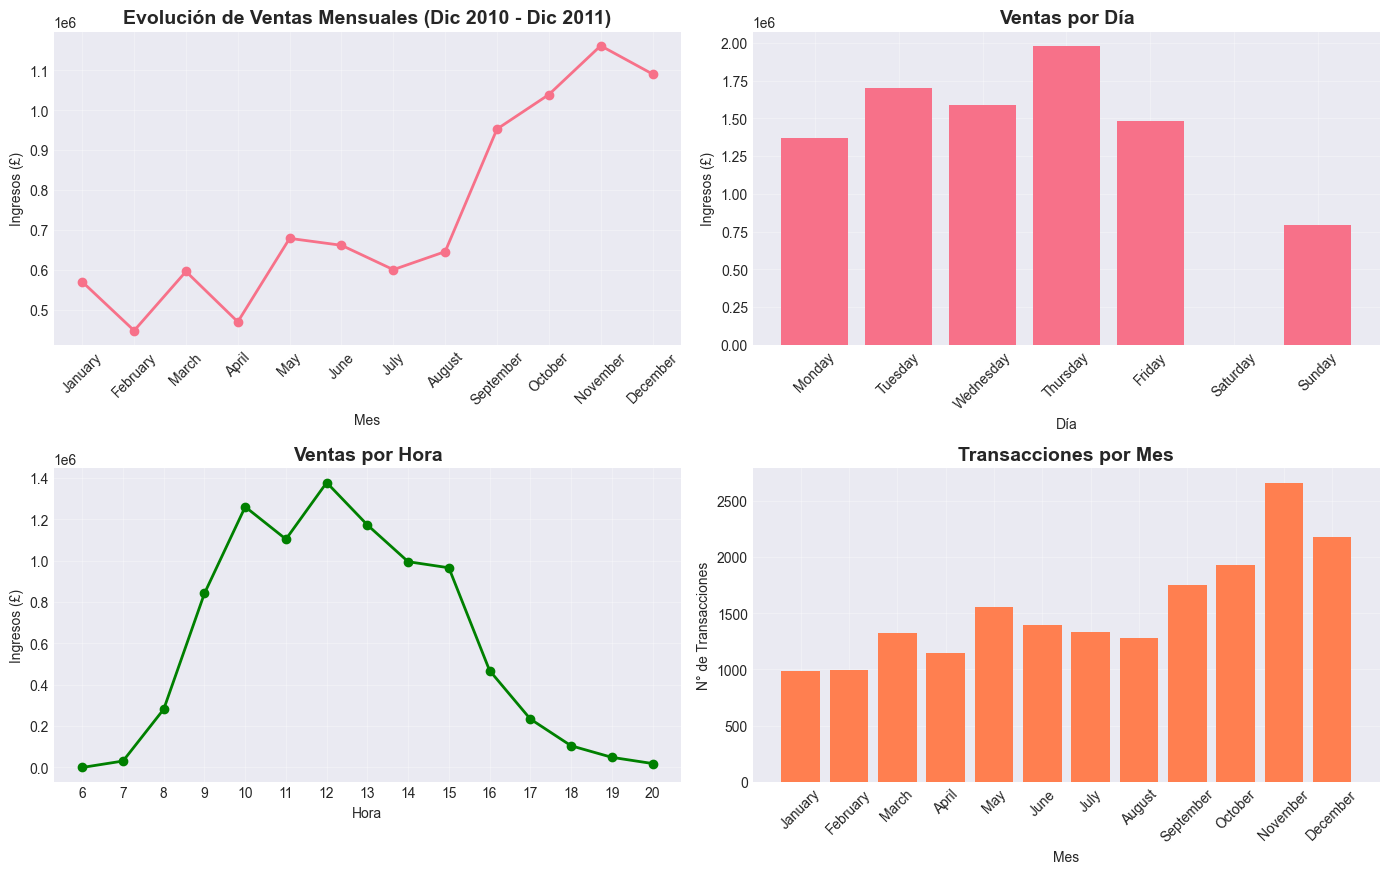

In [13]:
# Creamos series temporales adicionales para los otros gráficos
# Ventas por día
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_sales = df_clean.groupby('DayOfWeek')['TotalPrice'].sum().reindex(day_order)
# Ventas por hora
hourly_sales = df_clean.groupby('Hour')['TotalPrice'].sum()
# Transacciones por mes
monthly_transactions = df_clean.groupby('MonthName')['InvoiceNo'].nunique().reindex([
    'January', 'February', 'March', 'April', 'May', 'June', 'July', 'August', 'September', 'October', 'November', 'December'
])
fig, axes = plt.subplots(2, 2, figsize=(14,9))
# graficaremos 4 análisis temporales diferentes
# graph_type puede ser "line" o "bar"
# 1. Evolución de Ventas Mensuales (Dic 2010 - Dic 2011)
plot_graph(
    ax = axes[0,0],
    x = monthly_sales.index,
    y = monthly_sales.values,
    title="Evolución de Ventas Mensuales (Dic 2010 - Dic 2011)",
    xlabel="Mes",
    ylabel="Ingresos (£)",
    graph_type="line",
    rotation=45
)


# 2. Ventas por día
plot_graph(
    ax = axes[0,1],
    x = day_sales.index,
    y = day_sales.values,
    title="Ventas por Día",
    xlabel="Día",
    ylabel="Ingresos (£)",
    graph_type="bar",
    rotation=45
)

# 3. Ventas por hora
plot_graph(
    ax = axes[1,0],
    x = hourly_sales.index,
    y = hourly_sales.values,
    title="Ventas por Hora",
    xlabel="Hora",
    ylabel="Ingresos (£)",
    graph_type="line",
    color="green"
)

# 4. Transacciones por mes
plot_graph(
    ax = axes[1,1],
    x = monthly_transactions.index,
    y = monthly_transactions.values,
    title="Transacciones por Mes",
    xlabel="Mes",
    ylabel="N° de Transacciones",
    graph_type="bar",
    rotation=45,
    color="coral"
)

plt.tight_layout()
plt.savefig('../images/Tendencia de Ventas y Transacciones.png', dpi=300, bbox_inches='tight')
plt.show()

## 7. Análisis de Productos


In [14]:
print("\n\n📦 ANÁLISIS DE PRODUCTOS")
print("="*50)

# Top productos por ingresos
product_revenue = df_clean.groupby('Description').agg({
    'TotalPrice': 'sum',
    'Quantity': 'sum',
    'InvoiceNo': 'nunique'
}).round(2)

product_revenue.columns = ['Revenue', 'Units_Sold', 'Transactions']
product_revenue = product_revenue.sort_values('Revenue', ascending=False)

print("\nTop 10 productos por ingresos:")
print(product_revenue.head(10))



📦 ANÁLISIS DE PRODUCTOS

Top 10 productos por ingresos:
                                      Revenue  Units_Sold  Transactions
Description                                                            
PAPER CRAFT , LITTLE BIRDIE         168469.60       80995             1
REGENCY CAKESTAND 3 TIER            142592.95       12402          1703
WHITE HANGING HEART T-LIGHT HOLDER  100448.15       36725          1971
JUMBO BAG RED RETROSPOT              85220.78       46181          1600
MEDIUM CERAMIC TOP STORAGE JAR       81416.73       77916           195
POSTAGE                              77803.96        3120          1099
PARTY BUNTING                        68844.33       15291          1379
ASSORTED COLOUR BIRD ORNAMENT        56580.34       35362          1375
Manual                               53779.93        7173           253
RABBIT NIGHT LIGHT                   51346.20       27202           801


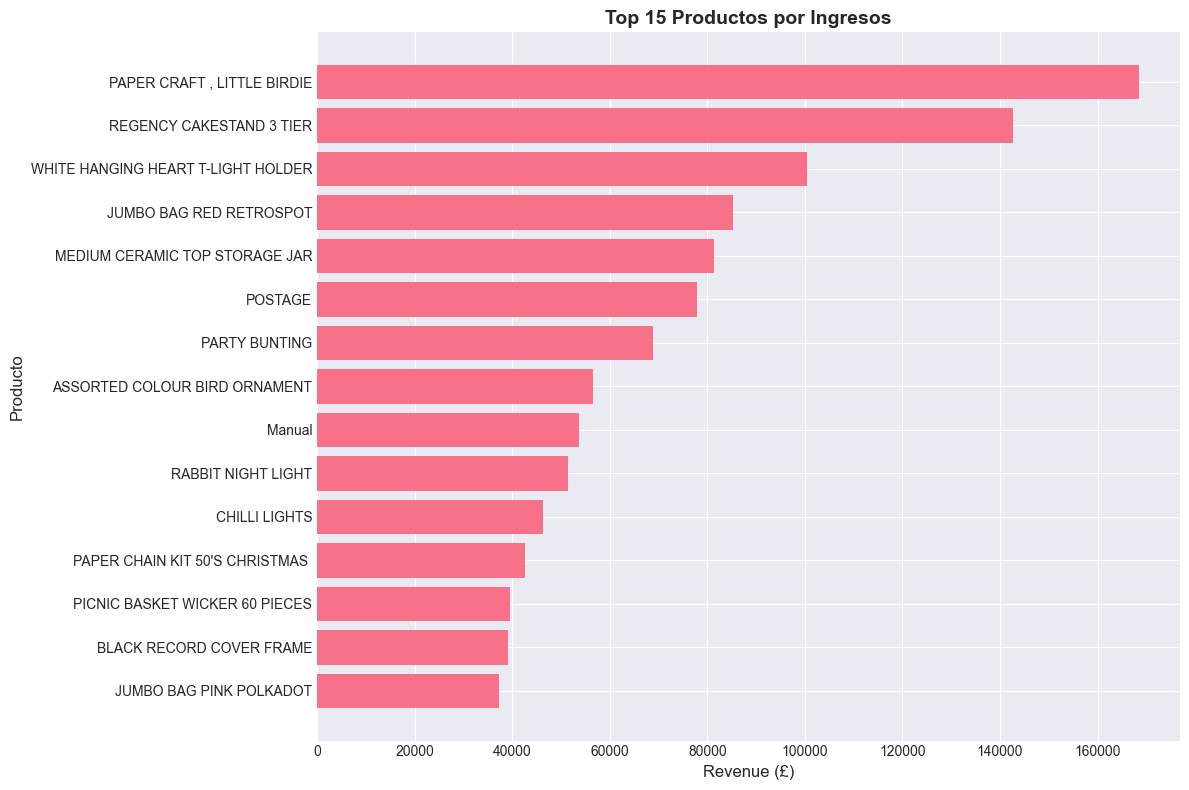

In [15]:
# Visualización
plt.figure(figsize=(12, 8))
top_products = product_revenue.head(15)
plt.barh(range(len(top_products)), top_products['Revenue'])
plt.yticks(range(len(top_products)), top_products.index, fontsize=10)
plt.xlabel('Revenue (£)', fontsize=12)
plt.ylabel('Producto', fontsize=12)
plt.title('Top 15 Productos por Ingresos', fontsize=14, fontweight='bold')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('../images/Productos_por_Ingresos.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. ANÁLISIS DE CLIENTES (RFM)
**En este espacio realizaremos un análisis RFM (Recencia, Frecuencia, Valor Monetario) para segmentar a los clientes según su comportamiento de compra.**

In [16]:
print("\n\n👥 ANÁLISIS RFM DE CLIENTES")
print("="*50)

# Calcular RFM
snapshot_date = df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x: (snapshot_date - x.max()).days,  # Recency
    'InvoiceNo': 'nunique',  # Frequency
    'TotalPrice': 'sum'  # Monetary
})

rfm.columns = ['Recency', 'Frequency', 'Monetary']
rfm = rfm.round(2)

print("\nEstadísticas RFM:")
print(rfm.describe())



👥 ANÁLISIS RFM DE CLIENTES

Estadísticas RFM:
           Recency    Frequency       Monetary
count  4338.000000  4338.000000    4338.000000
mean     92.536422     4.272015    2054.266459
std     100.014169     7.697998    8989.230441
min       1.000000     1.000000       3.750000
25%      18.000000     1.000000     307.415000
50%      51.000000     2.000000     674.485000
75%     142.000000     5.000000    1661.740000
max     374.000000   209.000000  280206.020000


In [17]:
# Segmentación RFM
rfm['R_Score'] = pd.qcut(rfm['Recency'], 4, labels=[4, 3, 2, 1])
rfm['F_Score'] = pd.qcut(rfm['Frequency'].rank(method='first'), 4, labels=[1, 2, 3, 4])
rfm['M_Score'] = pd.qcut(rfm['Monetary'], 4, labels=[1, 2, 3, 4])

rfm['RFM_Score'] = rfm['R_Score'].astype(str) + rfm['F_Score'].astype(str) + rfm['M_Score'].astype(str)

# Top clientes
print("\nTop 10 clientes por valor monetario:")
print(rfm.sort_values('Monetary', ascending=False).head(10))



Top 10 clientes por valor monetario:
            Recency  Frequency   Monetary R_Score F_Score M_Score RFM_Score
CustomerID                                                                 
14646.0           2         73  280206.02       4       4       4       444
18102.0           1         60  259657.30       4       4       4       444
17450.0           8         46  194550.79       4       4       4       444
16446.0           1          2  168472.50       4       2       4       424
14911.0           1        201  143825.06       4       4       4       444
12415.0          24         21  124914.53       3       4       4       344
14156.0          10         55  117379.63       4       4       4       444
17511.0           3         31   91062.38       4       4       4       444
16029.0          39         63   81024.84       3       4       4       344
12346.0         326          1   77183.60       1       1       4       114


In [18]:
def plot_rfm(ax, rfm, score ,title, xlabel="", ylabel="", graph_type="hist", rotation=0, color=None):
    """
    ax         → axes[x, y] donde se va a graficar
    x, y       → datos
    title      → título del gráfico
    graph_type → hist
    color      → opcional
    """
    ax.hist(rfm[score], bins=50, color=color, edgecolor='black')

    ax.set_title(title, fontsize=14, fontweight="bold")
    ax.set_xlabel(xlabel, fontsize=12)
    ax.set_ylabel(ylabel, fontsize=12)


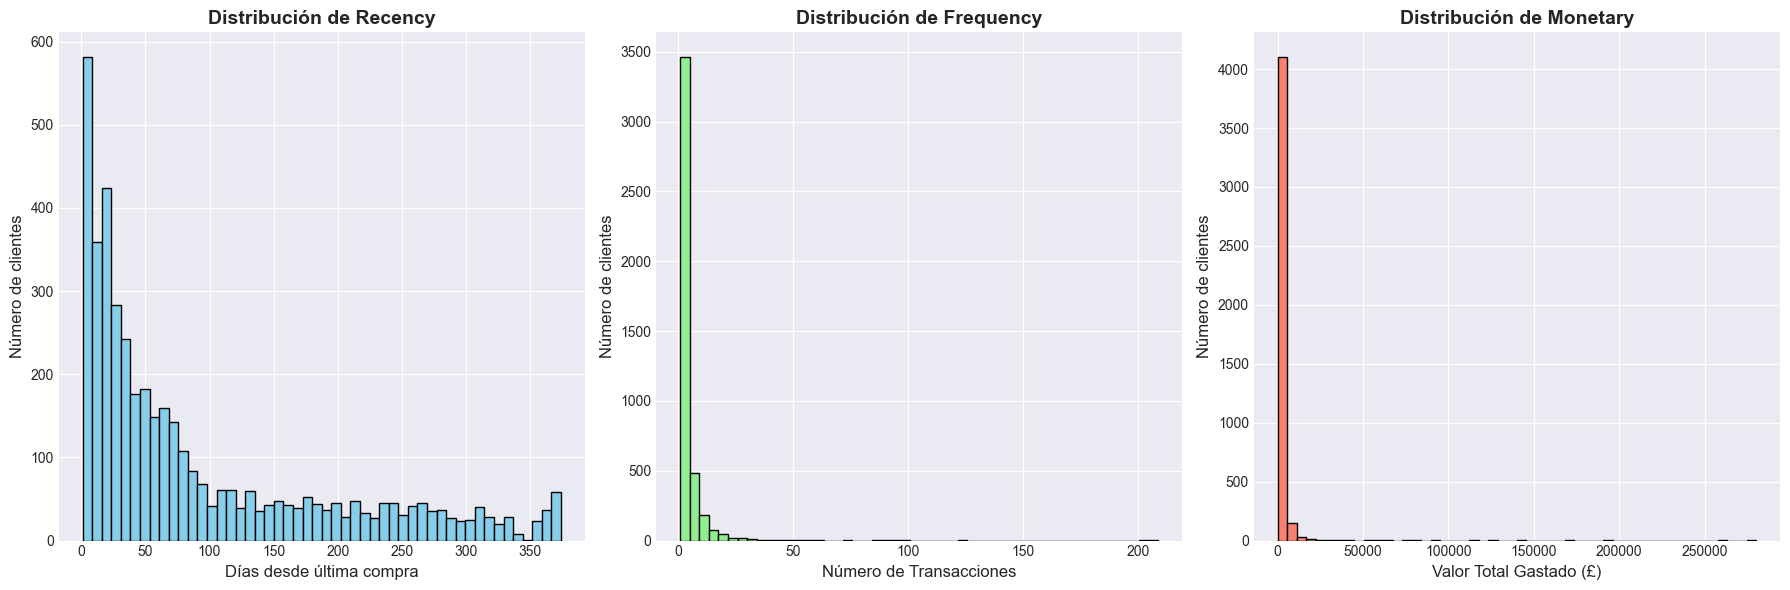

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
plot_rfm(
    ax = axes[0],
    rfm = rfm,
    score= 'Recency', # Recency es el tiempo desde la última compra
    title="Distribución de Recency",
    xlabel="Días desde última compra",
    ylabel="Número de clientes",
    color='skyblue',
    rotation=45
)
plot_rfm(
    ax = axes[1],
    rfm = rfm,
    score= 'Frequency', # Recency es el tiempo desde la última compra
    title="Distribución de Frequency",
    xlabel="Número de Transacciones",
    ylabel="Número de clientes",
    color='lightgreen',
    rotation=45
)
plot_rfm(
    ax = axes[2],
    rfm = rfm,
    score= 'Monetary', # Recency es el tiempo desde la última compra
    title="Distribución de Monetary",
    xlabel="Valor Total Gastado (£)",
    ylabel="Número de clientes",
    color='salmon',
    rotation=45
)
plt.tight_layout()
plt.savefig('../images/rfm_analysis.png', dpi=300, bbox_inches='tight')
plt.show()

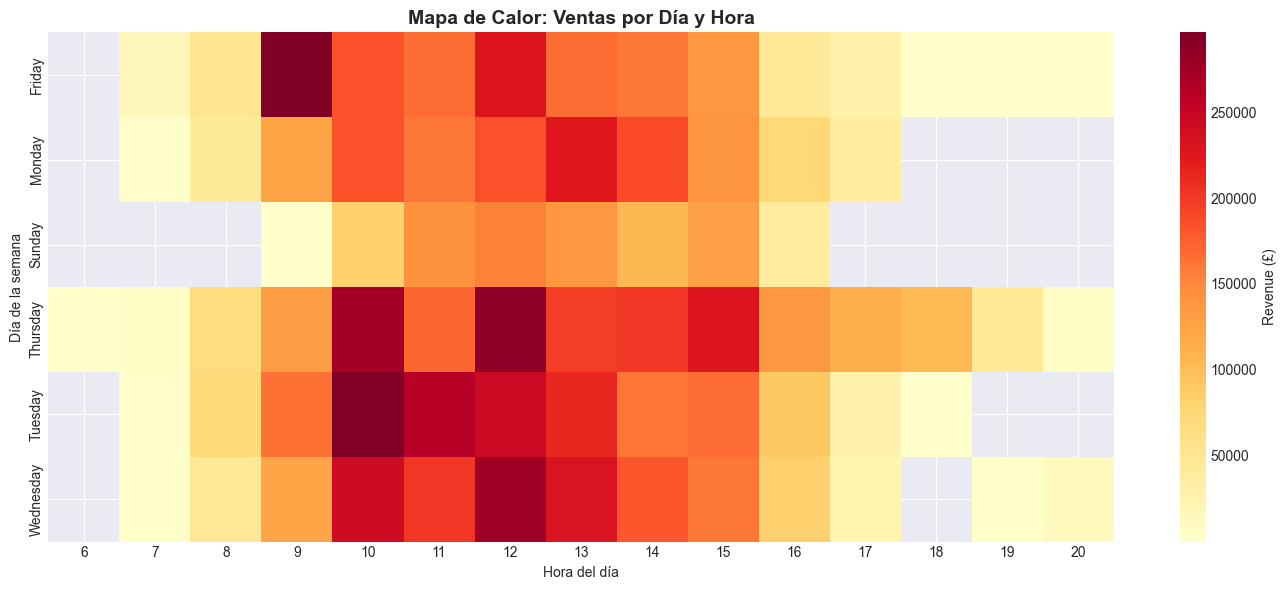

In [20]:
# MAPA DE CALOR: Ventas por Día x Hora
pivot_heatmap = df_clean.groupby(['DayOfWeek', 'Hour'])['TotalPrice'].sum().unstack()
plt.figure(figsize=(14, 6))
sns.heatmap(pivot_heatmap, cmap='YlOrRd', annot=False, fmt='.0f', cbar_kws={'label': 'Revenue (£)'})
plt.title('Mapa de Calor: Ventas por Día y Hora', fontsize=14, fontweight='bold')
plt.xlabel('Hora del día')
plt.ylabel('Día de la semana')
plt.tight_layout()
plt.savefig('../images/heatmap_day_hour.png', dpi=300)
plt.show()

📝 Conclusión del Mapa de Calor – Ventas por Día y Hora

El análisis de ventas por franja horaria revela patrones claros de comportamiento del consumidor:

🔥 El mayor volumen de ventas ocurre entre 10:00 y 14:00, principalmente los días Miércoles, Jueves y Viernes.

📉 A partir de las 17:00 las ventas disminuyen considerablemente, lo que indica baja actividad de compra en la tarde-noche.

🏆 Los horarios con ingresos máximos identificados fueron:

Viernes 9:00 AM

Jueves 10:00 AM

Jueves 12:00 PM

🛍 Los días menos activos fueron Domingo y Lunes, sugiriendo que campañas o promociones tienen menor impacto en esas fechas.

📌 Recomendación de negocio: enfocarse en promociones, email marketing y lanzamientos de productos entre semana en el bloque 9–14h, cuando la conversión es más alta.

In [21]:
print("\n✅ Análisis completado exitosamente!")
print("📁 Gráficos guardados en la carpeta 'images/'")


✅ Análisis completado exitosamente!
📁 Gráficos guardados en la carpeta 'images/'


## 💡 **INSIGHTS CLAVE**
---

### 📍 **1. Mercado Principal**
- Reino Unido representa el mayor porcentaje de ingresos.  
- Existe oportunidad de expansión hacia otros mercados europeos.

---

### ⏳ **2. Temporalidad**
- **Noviembre es el mes con mayores ventas** (pico por temporada navideña).  
- **Horas pico:** 10 AM – 3 PM.  
- Mayor actividad **de lunes a viernes**.

---

### 🛍 **3. Productos**
- Productos de **decoración y regalos** son los más solicitados.  
- Alto volumen de **transacciones pequeñas → ticket promedio bajo**.

---

### 👥 **4. Clientes**
- Concentración de ingresos bajo el principio **80/20**.  
- Se recomienda implementar **programas de fidelización**.  
- Alta oportunidad en clientes con **recency elevada** (potencial reactivación).

---

## 📈 **Recomendaciones Estratégicas**
- ✔ Implementar **campañas de retención** para clientes de alto valor.  
- ✔ Optimizar **inventario según estacionalidad** del consumo.  
- ✔ Potenciar **cross-selling** durante horas de mayor actividad.  
- ✔ Diseñar **programas de reactivación de clientes inactivos**.  
- ✔ Expandir marketing hacia mercados emergentes (Alemania, Francia, etc.).
